# Orebit synthetic datasets: a visual tour

What the five datasets look like, file by file. Everything here is **synthetic**
(CC BY 4.0), generated by the models in `_generator/`.

| Folder | What it is |
|---|---|
| `01-emas-epitermal` | Epithermal gold-silver vein, angled holes |
| `02-nikel-laterit` | Nickel laterite, vertical holes |
| `03-timah-placer` | Alluvial tin in a buried palaeochannel |
| `04-emas-open-pit` | Open-pit gold: drillholes + topography + block model |
| `05-nikel-laterit-open-pit` | Open-pit nickel laterite: drillholes + topography + block model |

Run it in Colab or locally; the first cell fetches the repository if needed.

In [ ]:
import os, subprocess, sys
if not os.path.exists("_generator/make_preview.py"):
    if os.path.exists("../_generator/make_preview.py"):
        os.chdir("..")
    else:  # e.g. Google Colab
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/ghoziankarami/orebit-datasets.git"], check=True)
        os.chdir("orebit-datasets")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib", "plotly"], check=True)
sys.path.insert(0, "_generator")
import pandas as pd
import make_preview as mp
from IPython.display import Image, display
pd.set_option("display.width", 140)

## 1. The files

Every dataset has the same four drillhole tables. Lines starting with `#` in a CSV
are metadata (CRS, datum) and are skipped with `comment="#"`. Blank cells mean *missing*, never zero.
Here is `04-emas-open-pit`, the complete package.

In [ ]:
d = "04-emas-open-pit"
t = mp.load(d)
for name, df in t.items():
    print(f"--- {name}.csv  ({len(df):,} rows)")
    display(df.head(4))

--- collar.csv  (104 rows)


,BHID,XCOLLAR,YCOLLAR,ZCOLLAR,TD
0,GK-001,520200.37,9180200.21,372.71,183.9
1,GK-002,520300.72,9180197.85,399.35,175.5
2,GK-003,520401.53,9180201.50,429.20,161.4
3,GK-004,520494.88,9180202.43,432.49,174.4


--- survey.csv  (794 rows)


,BHID,AT,AZ,DIP
0,GK-001,0.0,235.9,60.1
1,GK-001,30.0,236.1,59.8
2,GK-001,60.0,236.1,59.2
3,GK-001,90.0,237.3,58.7


--- assay.csv  (12,669 rows)


,BHID,FROM,TO,AU_GPT,AG_GPT,SG
0,GK-001,0.0,2.0,0.018,0.06,2.15
1,GK-001,2.0,4.0,0.026,0.19,2.16
2,GK-001,4.0,6.0,0.005,0.10,2.15
3,GK-001,6.0,8.0,0.010,0.12,2.18


... (2 outputs left out)

--- block_model.csv  (116,056 rows)


,X,Y,Z,DX,DY,DZ,DENSITY,DOMAIN,CLASS,AU_GPT,AG_GPT
0,520007.5,9180007.5,175.0,15.0,15.0,10.0,2.641,FRESH,Inferred,0.0165,0.076
1,520007.5,9180007.5,185.0,15.0,15.0,10.0,2.697,FRESH,Inferred,0.0360,0.149
2,520007.5,9180007.5,195.0,15.0,15.0,10.0,2.685,FRESH,Inferred,0.0050,0.160
3,520007.5,9180007.5,205.0,15.0,15.0,10.0,2.709,FRESH,Inferred,0.0246,0.144


--- surface_topo.csv  (3,481 rows)


,X,Y,Z
0,519950.0,9179950.0,351.942
1,519950.0,9179970.0,355.348
2,519950.0,9179990.0,357.416
3,519950.0,9180010.0,359.581


| Table | Columns | Meaning |
|---|---|---|
| `collar` | `BHID, XCOLLAR, YCOLLAR, ZCOLLAR, TD` | Hole start (UTM metres, elevation Z up) and total depth |
| `survey` | `BHID, AT, AZ, DIP` | Downhole direction. `DIP` is positive downward, 90 = vertical |
| `assay` | `BHID, FROM, TO, <grades>, SG` | Sample intervals with grades (unit in the column name) |
| `litho` | `BHID, FROM, TO, LITH [, ALT]` | Logged lithology (and alteration) |
| `block_model` | `X, Y, Z, DX, DY, DZ, DENSITY, DOMAIN, CLASS, <grades>` | Regular 3D model, X/Y/Z are block centres (open-pit sets only) |
| `surface_topo` | `X, Y, Z` | Topography grid (also as `surface_topo.dxf`, open-pit sets only) |

## 2. From intervals to 3D positions

Assays only carry depths (`FROM`/`TO`). To plot them, the hole path is computed from the
survey by *minimum curvature* (`desurvey()` in `_generator/common.py`).

In [ ]:
comp = mp.composites(t)
display(comp[["BHID", "FROM", "TO", "AU_GPT", "X", "Y", "Z"]].head())

,BHID,FROM,TO,AU_GPT,X,Y,Z
0,GK-001,0.0,2.0,0.018,520199.957143,9.180200e+06,371.843147
1,GK-001,2.0,4.0,0.026,520199.130956,9.180199e+06,370.109701
2,GK-001,4.0,6.0,0.005,520198.304138,9.180199e+06,368.376604
3,GK-001,6.0,8.0,0.010,520197.476688,9.180198e+06,366.643856
4,GK-001,8.0,10.0,0.009,520196.648607,9.180198e+06,364.911456


## 3. Preview of each dataset

Left: plan view (collars, hole traces, assay samples; topography contours when present).
Middle: a vertical section through the best-mineralised slab. Right (open-pit sets): one bench of the block model.
Colour is the main grade on a log scale for gold and tin, linear for nickel.

### `01-emas-epitermal`

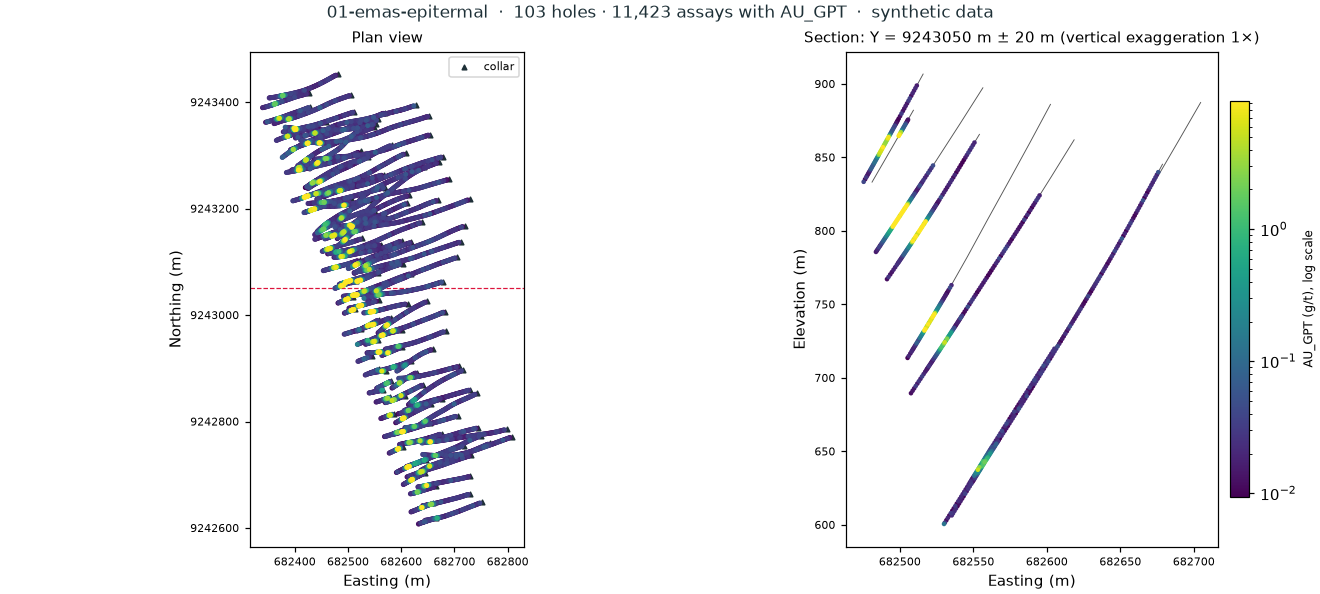

In [ ]:
display(Image(str(mp.draw_preview("01-emas-epitermal", out_dir="figures"))))

### `02-nikel-laterit`

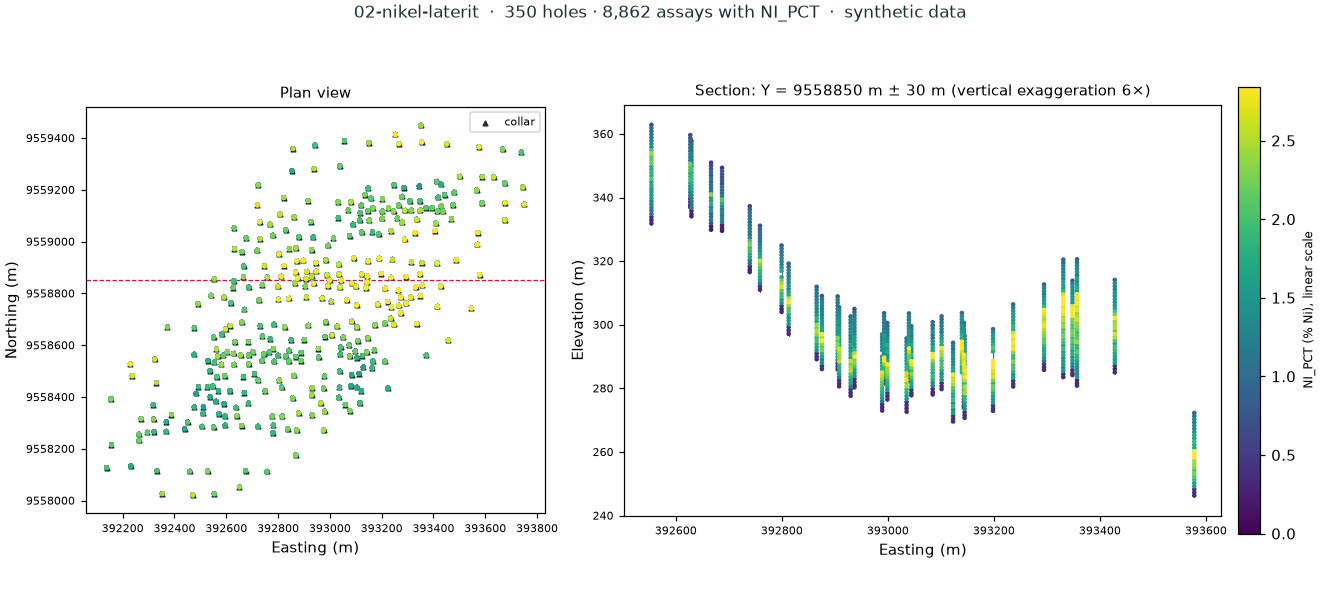

In [ ]:
display(Image(str(mp.draw_preview("02-nikel-laterit", out_dir="figures"))))

### `03-timah-placer`

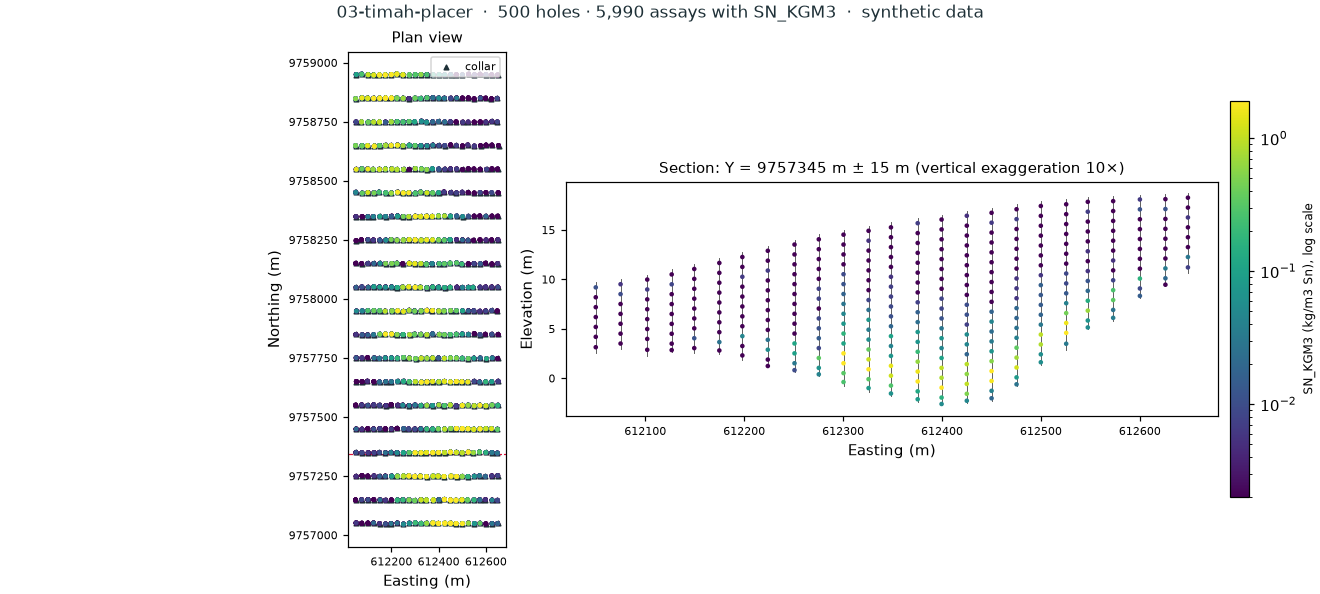

In [ ]:
display(Image(str(mp.draw_preview("03-timah-placer", out_dir="figures"))))

### `04-emas-open-pit`

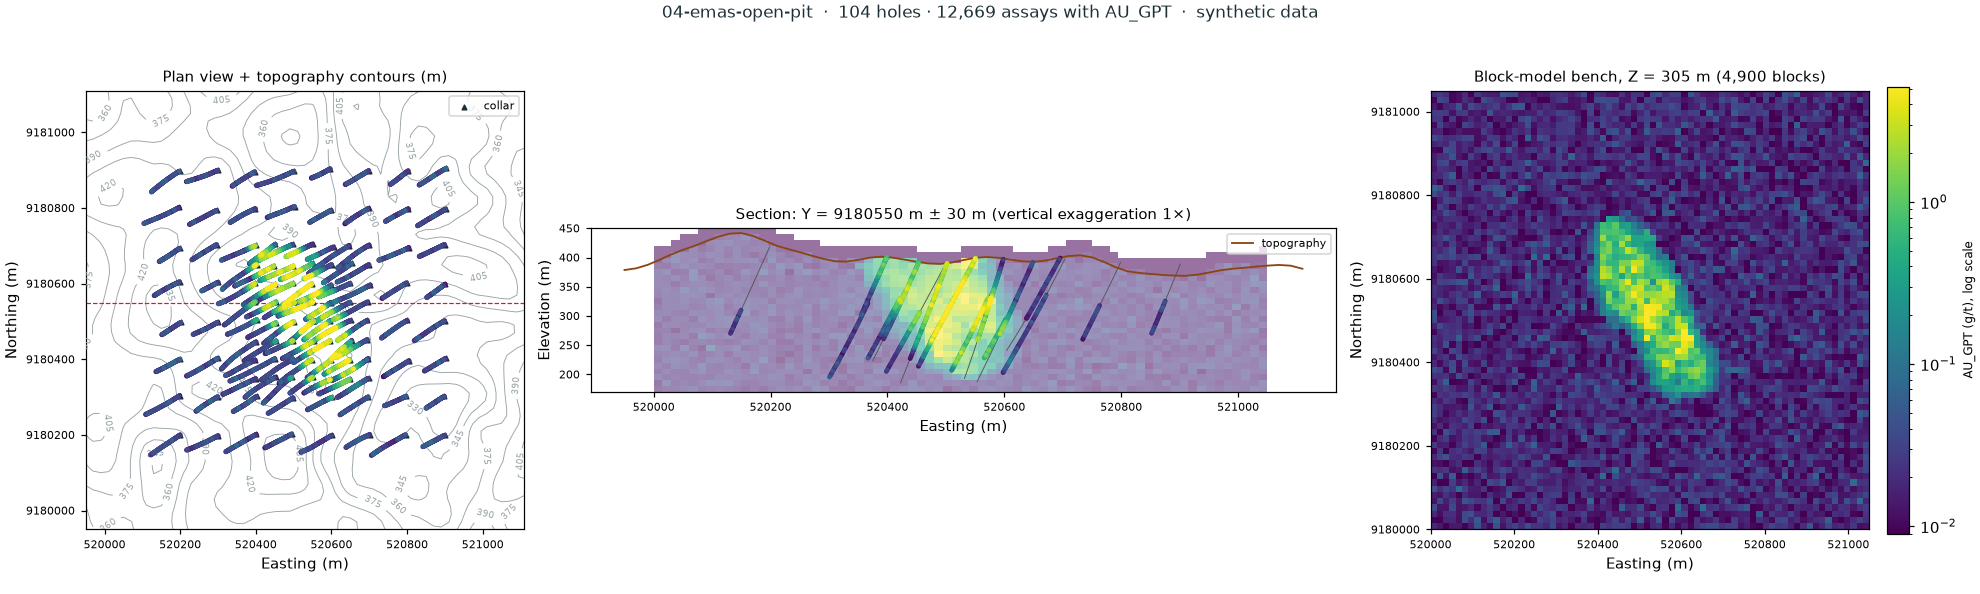

In [ ]:
display(Image(str(mp.draw_preview("04-emas-open-pit", out_dir="figures"))))

### `05-nikel-laterit-open-pit`

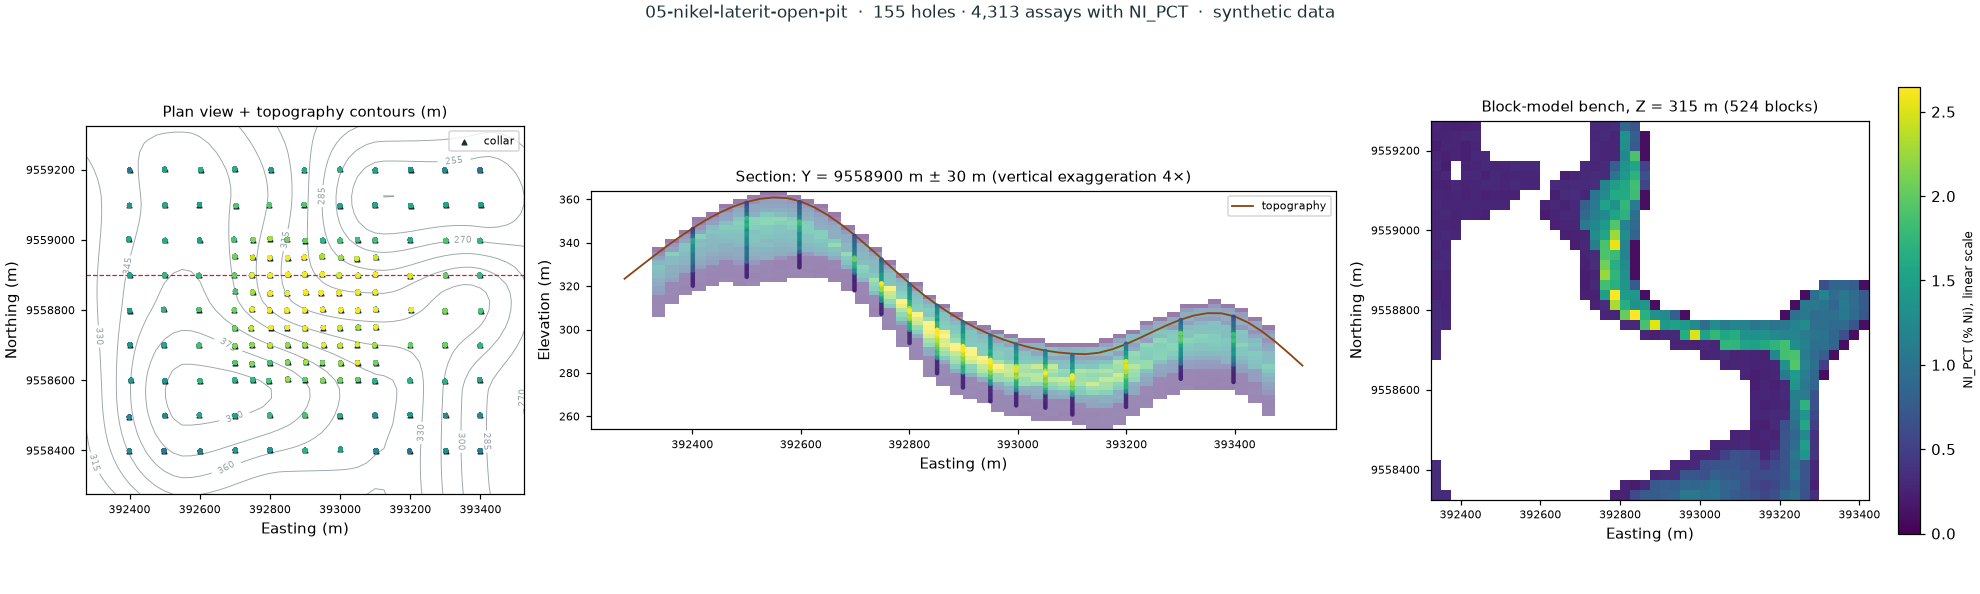

In [ ]:
display(Image(str(mp.draw_preview("05-nikel-laterit-open-pit", out_dir="figures"))))

## 4. Interactive 3D

Pre-built pages are in `docs/3d/` (download and open in a browser; they load plotly from a CDN).
The cell below shows the nickel open-pit set inline (needs Jupyter or Colab; GitHub does not run it). Click legend entries to toggle drillholes, samples and blocks above cut-off.

In [ ]:
fig = mp.figure_3d("05-nikel-laterit-open-pit")
fig.show()